# Who gets the carbon dividend?

Name: Juozapas (juozapask)

**Recommendation for the finance minister**

**Extra help for lower incomes, with a payment for everyone**

Give 75% equally; use 25% for extra income-based payments. Everyone gets about EUR 431. The extra payment shrinks as income rises and ends at EUR 77,325. Both plans return EUR 137,916.

The lowest 20% get 1.11% of income more back than they pay on average, up from 0.66%; 83% get more back than they pay, versus 79%. For the highest 20%, average cost after rebate rises from 0.20% to 0.35%; 10% get more back, versus 27%. Figure 1 shows charges differ for similar incomes.

Per person, the lowest 20% still get EUR 212 more back than they pay (EUR 139 under the equal plan). The plan still holds per person. Below EUR 77,325, each extra EUR 1,000 of income cuts the extra payment by EUR 4.18. Other taxes may matter. This data cannot show if people work less.

In [1]:
import numpy as np
import pandas as pd
import plotnine as pn
from pathlib import Path

# Use the packet file beside this notebook, or the course CSV one folder above.
data_path = Path("households.csv")
if not data_path.exists():
    data_path = Path("../households.csv")
h = pd.read_csv(data_path)
h["tax"] = 100 * (h["heat_t"] + h["travel_t"])
revenue = h["tax"].sum()
h["equal_dividend"] = revenue / len(h)
h["net_equal"] = h["tax"] - h["equal_dividend"]
print(f"{len(h)} fictional households | Total carbon charge EUR {revenue:,.2f} | Equal payment EUR {revenue / len(h):,.2f}")
print("Money left after equal plan (EUR):", round(revenue - h["equal_dividend"].sum(), 6))
assert abs(revenue - h["equal_dividend"].sum()) < 0.01

240 fictional households | Total carbon charge EUR 137,916.00 | Equal payment EUR 574.65
Money left after equal plan (EUR): 0.0


### Your goal and the new rule
*A carbon charge is money paid for pollution from heating and travel. Goal: help lower-income households, while keeping some payment for everyone. Give 75% of the money out equally. Use the other 25% for extra payments based on income. Lower incomes get a larger extra payment. It gets smaller as income rises and reaches zero at twice the middle income in this sample (EUR 77,325). The rule uses income from before the carbon charge, not a household's own emissions. It helps the priority because the extra payment is largest for the lowest incomes.*

In [2]:
# Divide a pool of money by household scores.
def distribute(weights, budget=revenue):
    weights = pd.Series(weights, index=h.index, dtype=float)
    assert np.isfinite(weights).all() and (weights >= 0).all() and weights.sum() > 0
    return budget * weights / weights.sum()

median_income = h["income_eur"].median()
taper_limit = 2 * median_income
h["income_score"] = np.clip(1 - h["income_eur"] / taper_limit, 0, 1)
equal_share = 0.75
targeted_share = 0.25
h["equal_base"] = equal_share * revenue / len(h)
h["targeted_topup"] = distribute(h["income_score"], budget=targeted_share * revenue)
h["proposal"] = h["equal_base"] + h["targeted_topup"]
h["net_rival"] = h["tax"] - h["proposal"]
print(f"Middle household income (EUR): {median_income:,.2f}")
print(f"Income where the extra payment ends (EUR): {taper_limit:,.2f}")
print(f"Money split: {equal_share:.0%} equal, {targeted_share:.0%} based on income")
print(f"Equal payment for each household (EUR): {h['equal_base'].iloc[0]:,.3f}")
print(f"Total extra payments (EUR): {h['targeted_topup'].sum():,.2f}")
print(f"Smallest to largest payment (EUR): {h['proposal'].min():,.3f} to {h['proposal'].max():,.3f}")

Middle household income (EUR): 38,662.50
Income where the extra payment ends (EUR): 77,325.00
Money split: 75% equal, 25% based on income
Equal payment for each household (EUR): 430.988
Total extra payments (EUR): 34,479.00
Smallest to largest payment (EUR): 430.988 to 707.216


In [3]:
print("Money left after new plan (EUR):", round(revenue - h["proposal"].sum(), 6))
assert h["proposal"].notna().all() and (h["proposal"] >= 0).all()
assert abs(h["proposal"].sum() - revenue) < 0.01

Money left after new plan (EUR): 0.0


### Table
*Each row shows 20% of households, sorted by income. Cost after rebate means carbon charge minus rebate. A negative number means the household got more back than it paid. The last columns show how many households got more back than they paid.*

In [4]:
h["quintile"] = pd.qcut(h["income_eur"], 5, labels=["Lowest 20%", "Second 20%", "Middle 20%", "Fourth 20%", "Highest 20%"])
h["pct_equal"] = h["net_equal"] / h["income_eur"] * 100
h["pct_rival"] = h["net_rival"] / h["income_eur"] * 100
h["gain_equal"] = h["net_equal"] < 0
h["gain_rival"] = h["net_rival"] < 0

table = h.groupby("quintile", observed=True).agg(
    households=("id", "size"),
    income_min=("income_eur", "min"),
    income_max=("income_eur", "max"),
    mean_tax=("tax", "mean"),
    equal_pct=("pct_equal", "mean"),
    rival_pct=("pct_rival", "mean"),
    equal_gain=("gain_equal", "mean"),
    rival_gain=("gain_rival", "mean"),
)
out = pd.DataFrame({
    "Households (number)": table["households"],
    "Income range (EUR/year)": [f"{a:,.0f} to {b:,.0f}" for a, b in zip(table["income_min"], table["income_max"])],
    "Mean carbon charge (EUR/year)": table["mean_tax"].round(0),
    "Cost after rebate: equal (% income)": table["equal_pct"].round(2),
    "Cost after rebate: new plan (% income)": table["rival_pct"].round(2),
    "Got more back, equal plan (%)": (table["equal_gain"] * 100).round(0),
    "Got more back, new plan (%)": (table["rival_gain"] * 100).round(0),
})
out.index.name = "Income group"
print("Table 1. Cost after rebate = carbon charge minus rebate. Negative means the household got more back than it paid.")
out

Table 1. Cost after rebate = carbon charge minus rebate. Negative means the household got more back than it paid.


,Households (number),Income range (EUR/year),Mean carbon charge (EUR/year),Cost after rebate: equal (% income),Cost after rebate: new plan (% income),"Got more back, equal plan (%)","Got more back, new plan (%)"
Income group,,,,,,,
Lowest 20%,48,"11,305 to 27,638",440.0,-0.66,-1.11,79.0,83.0
Second 20%,48,"27,713 to 34,123",523.0,-0.17,-0.33,73.0,77.0
Middle 20%,48,"34,306 to 43,777",472.0,-0.27,-0.32,73.0,75.0
Fourth 20%,48,"43,973 to 59,358",703.0,0.25,0.31,33.0,29.0
Highest 20%,48,"59,562 to 150,676",736.0,0.20,0.35,27.0,10.0


### Figure
*Each dot is one household. The left panel shows the equal plan; the right shows the new plan. Blue dots are below EUR 77,325; orange dots are at or above it. The black line marks zero: below it, the household got back more than it paid. The dashed line marks where extra payments end. Dots at similar incomes spread out because heating and travel charges differ.*

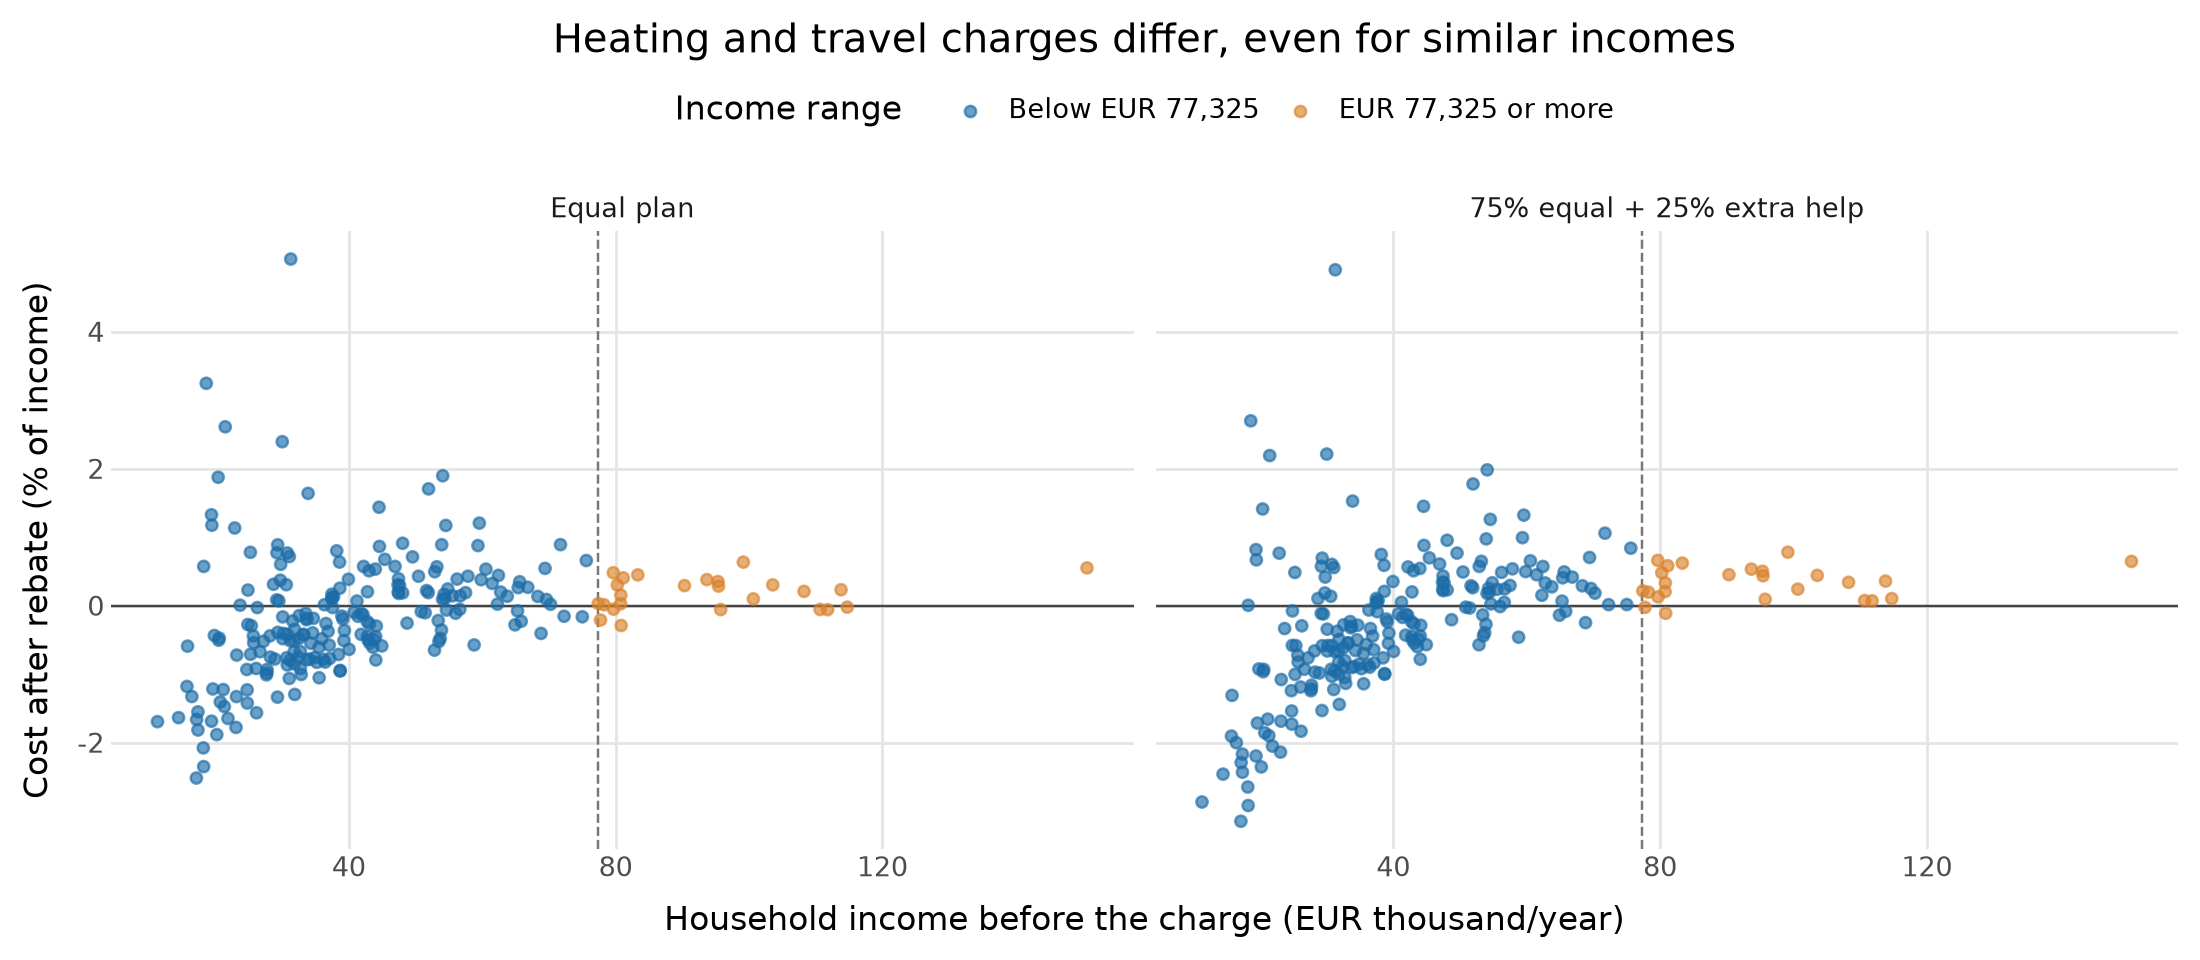

In [5]:
plot_data = h[["income_eur", "income_score", "pct_equal", "pct_rival"]].melt(
    id_vars=["income_eur", "income_score"],
    value_vars=["pct_equal", "pct_rival"],
    var_name="policy",
    value_name="cost_pct",
)
plot_data["policy"] = pd.Categorical(
    plot_data["policy"].map({
        "pct_equal": "Equal plan",
        "pct_rival": "75% equal + 25% extra help",
    }),
    categories=["Equal plan", "75% equal + 25% extra help"],
    ordered=True,
)
plot_data["income_thousands"] = plot_data["income_eur"] / 1000
cutoff_text = f"EUR {taper_limit:,.0f}"
plot_data["income_band"] = np.where(
    plot_data["income_score"] > 0,
    f"Below {cutoff_text}",
    f"{cutoff_text} or more",
)

figure = (
    pn.ggplot(
        plot_data,
        pn.aes("income_thousands", "cost_pct", color="income_band"),
    )
    + pn.geom_hline(yintercept=0, color="#444444", size=0.5)
    + pn.geom_vline(
        xintercept=taper_limit / 1000,
        color="#777777",
        linetype="dashed",
        size=0.5,
    )
    + pn.geom_point(alpha=0.65, size=1.8)
    + pn.facet_wrap("~policy", nrow=1)
    + pn.scale_color_manual(
        values={
            f"Below {cutoff_text}": "#1b6ca8",
            f"{cutoff_text} or more": "#d9822b",
        }
    )
    + pn.labs(
        title="Heating and travel charges differ, even for similar incomes",
        x="Household income before the charge (EUR thousand/year)",
        y="Cost after rebate (% of income)",
        color="Income range",
    )
    + pn.theme_minimal(base_size=12)
    + pn.theme(
        panel_grid_minor=pn.element_blank(),
        figure_size=(11, 4.8),
        legend_position="top",
    )
)
figure

### Check and AI note
*Check the result using net cost per person (EUR/year), instead of as a share of income. The code also compares different payment splits and checks an earlier rule.*

*AI check: AI suggested doubling the payment below middle income; I checked the budget and lowest 20% result (1.59% average gain), but kept it as an idea because payment drops EUR 383 above the line.*

**Hypothesis (a guess to test):** the big payment drop may make households try to stay below the income line. Check whether households near the line change their earnings.

In [6]:
h["pp_equal"] = h["net_equal"] / h["people"]
h["pp_rival"] = h["net_rival"] / h["people"]
challenge = h.groupby("quintile", observed=True).agg(
    equal_plan=("pp_equal", "mean"),
    new_plan=("pp_rival", "mean"),
)
challenge.columns = ["Equal plan (EUR/person/year)", "New plan (EUR/person/year)"]
challenge.index.name = "Income group"
print("Check: average cost after rebate per person. Negative means got more back than paid.")
print(challenge.round(0).to_string())

# Compare how different shares affect payments and the amount lost when income rises.
lowest = h["quintile"] == "Lowest 20%"
highest = h["quintile"] == "Highest 20%"
split_rows = []
for target_share in [0, 0.25, 0.50, 0.75, 1.0]:
    equal_share = 1 - target_share
    base = equal_share * revenue / len(h)
    dividend = base + distribute(h["income_score"], budget=target_share * revenue)
    net = h["tax"] - dividend
    pct_income = net / h["income_eur"] * 100
    lost_per_1000 = target_share * revenue / (h["income_score"].sum() * taper_limit) * 1000
    split_rows.append({
        "Extra-help share (%)": target_share * 100,
        "Equal payment (EUR/household)": base,
        "Rebate lost per EUR 1,000 more income (EUR)": lost_per_1000,
        "Lowest 20% cost after rebate (% income)": pct_income[lowest].mean(),
        "Lowest 20% got more back (%)": (net[lowest] < 0).mean() * 100,
        "Highest 20% cost after rebate (% income)": pct_income[highest].mean(),
        "Highest 20% got more back (%)": (net[highest] < 0).mean() * 100,
    })
split_sensitivity = pd.DataFrame(split_rows).set_index("Extra-help share (%)")
print()
print("Split check. Negative costs mean households got more back than they paid. More extra help gives lower incomes more money, but makes payments fall faster as income rises.")
print(split_sensitivity.round(2).to_string())

# Check the earlier AI-suggested rule as an idea for further testing.
step_weights = np.where(h["income_eur"] < median_income, 2.0, 1.0)
step_dividend = distribute(step_weights)
step_net_pct = (h["tax"] - step_dividend) / h["income_eur"] * 100
step_low = step_dividend[h["income_eur"] < median_income].iloc[0]
step_high = step_dividend[h["income_eur"] >= median_income].iloc[0]
print()
print("Earlier-rule check: double payment below middle income")
print(f"Money left over (EUR): {revenue - step_dividend.sum():.6f}")
print(f"Payment below / at or above middle income (EUR): {step_low:.2f} / {step_high:.2f}")
print(f"Lowest 20% average gain (% income), earlier rule: {-step_net_pct[lowest].mean():.2f}")
print(f"Lowest 20% average gain (% income), new plan: {-h.loc[lowest, 'pct_rival'].mean():.2f}")

Check: average cost after rebate per person. Negative means got more back than paid.
              Equal plan (EUR/person/year)  New plan (EUR/person/year)
Income group                                                          
Lowest 20%                          -139.0                      -212.0
Second 20%                           -47.0                       -73.0
Middle 20%                           -70.0                       -79.0
Fourth 20%                            29.0                        42.0
Highest 20%                           46.0                        87.0

Split check. Negative costs mean households got more back than they paid. More extra help gives lower incomes more money, but makes payments fall faster as income rises.
                      Equal payment (EUR/household)  Rebate lost per EUR 1,000 more income (EUR)  Lowest 20% cost after rebate (% income)  Lowest 20% got more back (%)  Highest 20% cost after rebate (% income)  Highest 20% got more back (%)
Extra-